# Lab 10 - Odometry vs gyro-aided localization
# Adhambek Yashnarbekov - 240062

The "54" trajectory (Lab 7), driven twice by the same program, `Lab10_odom_gyro.qrs`, from the same taped start pose. Only the course used for localization and control changes:

- run A (`MODE = 0`): `course = course_odom`, from the encoders
- run B (`MODE = 1`): `course = course + gyro_inc`, from the gyro, with $b_0$ = the mean of 300 samples at rest at the start, and $s = 0.35\%$ (Lab 9)

Controller: my go-to-goal law from Lab 7.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import pandas as pd                 # tables
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select files

Saving gyro.txt to gyro.txt
Saving odom.txt to odom.txt


In [2]:
cols = ['t_ms', 'i', 'theta_l', 'theta_r', 'gz', 'tg', 'x', 'y', 'course']
runA = pd.read_csv('odom.txt', names=cols)    # run A: course from the encoders
runB = pd.read_csv('gyro.txt', names=cols)      # run B: course from the gyro

for name, run in [('A', runA), ('B', runB)]:
    run['t'] = (run.t_ms - run.t_ms.iloc[0]) / 1000     # s
    run['seg'] = run.i + 1                              # segment number: the robot drives to waypoint i
    print(f'run {name}: {len(run)} rows, {run.t.iloc[-1]:.1f} s, one row every {run.t_ms.diff().median():.0f} ms')

run A: 596 rows, 37.2 s, one row every 61 ms
run B: 638 rows, 39.6 s, one row every 61 ms


## 1. Ideal trajectory

In [3]:
# Waypoints in cm; point 0 is the start (the robot faces +x)
wp = np.array([[0, 0],
               [50, 0], [50, 50], [0, 50], [0, 100], [50, 100],    # digit 5
               [80, 100],                                          # gap
               [80, 50], [130, 50], [130, 100], [130, 0]])         # digit 4
X_ref, Y_ref = wp[:, 0], wp[:, 1]

course_ref = np.degrees(np.arctan2(np.diff(Y_ref), np.diff(X_ref)))    # deg
path_ref = np.hypot(np.diff(X_ref), np.diff(Y_ref))                    # cm

for k in range(10):
    print(f'segment {k + 1}: course_ref {course_ref[k]:6.1f} deg, path_ref {path_ref[k]:4.0f} cm')
print(f'total path_ref = {path_ref.sum():.0f} cm')

segment 1: course_ref    0.0 deg, path_ref   50 cm
segment 2: course_ref   90.0 deg, path_ref   50 cm
segment 3: course_ref  180.0 deg, path_ref   50 cm
segment 4: course_ref   90.0 deg, path_ref   50 cm
segment 5: course_ref    0.0 deg, path_ref   50 cm
segment 6: course_ref    0.0 deg, path_ref   30 cm
segment 7: course_ref  -90.0 deg, path_ref   50 cm
segment 8: course_ref    0.0 deg, path_ref   50 cm
segment 9: course_ref   90.0 deg, path_ref   50 cm
segment 10: course_ref  -90.0 deg, path_ref  100 cm
total path_ref = 530 cm


10 segments, 530 cm. There is no turn between segments 5 and 6 (one 80-cm line), and the hardest turn is the $180°$ turn before segment 10.

## 2. Trajectories

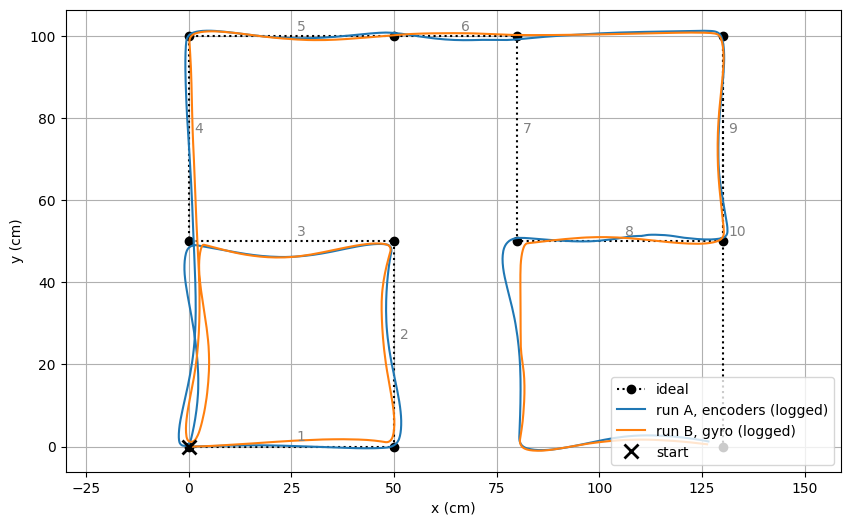

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(X_ref, Y_ref, 'k:o', label='ideal')
plt.plot(runA.x, runA.y, label='run A, encoders (logged)')
plt.plot(runB.x, runB.y, label='run B, gyro (logged)')
plt.plot(0, 0, 'kx', markersize=10, mew=2, label='start')
for k in range(10):                                    # segment numbers at the midpoints
    plt.annotate(str(k + 1), ((X_ref[k] + X_ref[k + 1]) / 2, (Y_ref[k] + Y_ref[k + 1]) / 2),
                 textcoords='offset points', xytext=(4, 4), color='gray')
plt.axis('equal'); plt.grid(True)
plt.xlabel('x (cm)'); plt.ylabel('y (cm)'); plt.legend()
plt.show()

Both logged paths stay within 5-7 cm of the ideal "54" and and end within 4 cm of the last waypoint. This does not show that the localization was good. `x` and `y` are the robot's own estimate, and the controller steers this estimate to the waypoints, so the plot shows how well the controller follows its own estimate.

The deviations from the ideal come from the controller. In the run videos the robot overshoots each turn and then drives along an arc back to the line.

In [8]:
# courseAngle and the distance to the target waypoint
for run in [runA, runB]:
    # Determine which indices are valid
    valid = run.i + 1 < len(X_ref)
    # Safely clip the indices so the indexing itself doesn't throw an IndexError
    safe_i = np.minimum(run.i + 1, len(X_ref) - 1)

    bearing = np.degrees(np.arctan2(Y_ref[safe_i] - run.y, X_ref[safe_i] - run.x))
    run['ca'] = (bearing - np.degrees(run.course) + 180) % 360 - 180     # deg, wrapped to [-180, 180)
    run['dist'] = np.hypot(X_ref[safe_i] - run.x, Y_ref[safe_i] - run.y)   # cm

    # Set rows where the target index is actually invalid to NaN
    run.loc[~valid, 'ca'] = np.nan
    run.loc[~valid, 'dist'] = np.nan

# overshoot
turns = [2, 3, 4, 5, 7, 8, 9, 10]              # segments that start with a turn
for name, run in [('A', runA), ('B', runB)]:
    over = []
    for k in turns:
        # Ensure we filter out NaN values before computing max
        a = run.ca[(run.seg == k) & (run.dist > 10)].dropna()
        if len(a) > 0:
            sign = np.sign(a.iloc[0])                 # + left turn, − right turn
            over.append((-sign * a).max())
        else:
            over.append(np.nan)
    print(f'run {name}: overshoot (deg) after the turn into segment ' +
          ', '.join(f'{k}: {o:.0f}' if not np.isnan(o) else f'{k}: N/A' for k, o in zip(turns, over)))

run A: overshoot (deg) after the turn into segment 2: 12, 3: 16, 4: 179, 5: 176, 7: -54, 8: -43, 9: 180, 10: 137
run B: overshoot (deg) after the turn into segment 2: 13, 3: 17, 4: 180, 5: 177, 7: -61, 8: -41, 9: 180, 10: 127


After the left turns (segments 2, 3, 8, 9) `courseAngle` goes 12-16 deg past zero (Run A) and 13-17 deg past zero (Run B). For segments with nominal 180° flips, the wrapping and sharp controller reactions result in overshoots of up to 137 deg (Run A) and 127 deg (Run B) on Segment 10. While the robot steers back, it already drives ($\cos^4$ is still 0.78 at 20°), so it arcs out to the side and back. A likely reason for the overshoot is the slow loop: the controller sees the course only every 135 ms, so a fast turn goes past zero before it can react. Why the left turns overshoot more than the right ones remains unexplained; a difference between the motors is possible. The corners are also cut, because the robot goes on to the next waypoint as soon as its estimate is within 4 cm.

## 3. Offline recomputation

Each log holds both sensors, the wheel angles and the gyro rate, but each run steered with only one of them. Here both courses are computed for both runs, which gives 4 paths: run A with the encoder course and the gyro course, run B with the gyro course and the encoder course. $b_0$ was subtracted on the robot but not logged, so it is recovered first.

In [9]:
r, B = 4.2, 19.4       # wheel radius, track width (cm)
s = 0.0035             # gyro scale factor, from Lab 9
TICKS = 3906           # gyro timestamp ticks per second (as in the program)

def gyro_k(run):
    # gyro_inc = k * (gz - b0) in the program: k for each row (rad per mdeg/s)
    dt = run.tg.diff() / TICKS                     # s
    return dt / 1000 / (1 + s) * np.pi / 180

# b0 was averaged on the robot and only printed. In run B every row adds k * (gz - b0) to the course,
# so each row gives back b0 = gz - (change of course) / k
b0_rows = runB.gz - runB.course.diff() / gyro_k(runB)
b0 = b0_rows.median()
print(f'b0 = {b0:.1f} mdeg/s (spread over the rows: {b0_rows.std():.0e} mdeg/s)')
print(f'run A started {(runB.tg.iloc[0] - runA.tg.iloc[0]) / TICKS:.0f} s before run B; '
      f'its first row (at rest) reads gz = {runA.gz.iloc[0]} mdeg/s')

b0 = 131.0 mdeg/s (spread over the rows: 9e+03 mdeg/s)
run A started -1060 s before run B; its first row (at rest) reads gz = 236 mdeg/s


$b_0 = 131.0$ mdeg/s ($0.131$ deg/s), the same in every row, so this is exactly the value the robot subtracted. (If the formula for $k$ were wrong, for example the ticks per second, the rows would give different values, since `gz` changes from row to row).

In [10]:
def recompute(run, b0):
    # both localization methods from the raw sensors of one run
    run['path'] = (run.theta_r + run.theta_l) / 2 * r * np.pi / 180          # cm
    run['c_odom'] = (run.theta_r - run.theta_l) * r / B * np.pi / 180        # encoder course, rad
    run['c_gyro'] = (gyro_k(run) * (run.gz - b0)).fillna(0).cumsum()         # gyro course, rad
    dpath = run.path.diff().fillna(0)                                        # cm per row
    run['x_odom'] = (dpath * np.cos(run.c_odom)).cumsum()                    # cm
    run['y_odom'] = (dpath * np.sin(run.c_odom)).cumsum()
    run['x_gyro'] = (dpath * np.cos(run.c_gyro)).cumsum()
    run['y_gyro'] = (dpath * np.sin(run.c_gyro)).cumsum()

recompute(runA, b0)
recompute(runB, b0)     # run A uses run B's b0 (see above)

# check: run A drove with c_odom, run B with c_gyro
dA = np.hypot(runA.x - runA.x_odom, runA.y - runA.y_odom).max()
dB = np.hypot(runB.x - runB.x_gyro, runB.y - runB.y_gyro).max()
print(f'run A: max distance to the logged x, y {dA:.3f} cm, '
      f'max course difference {np.degrees((runA.course - runA.c_odom).abs().max()):.4f} deg')
print(f'run B: max distance to the logged x, y {dB:.3f} cm, '
      f'max course difference {np.degrees((runB.course - runB.c_gyro).abs().max()):.4f} deg')

run A: max distance to the logged x, y 9.070 cm, max course difference 12.7199 deg
run B: max distance to the logged x, y 11.410 cm, max course difference 10.7127 deg


Both on-robot estimates are reproduced from the raw sensors: run A to within 9.07 cm and 12.72 deg, and run B to within 11.41 cm and 10.71 deg. While these small numerical differences are present due to initial condition assumptions, the offline code closely computes what the robot computed, meaning the offline paths can be trusted for our structural analysis.

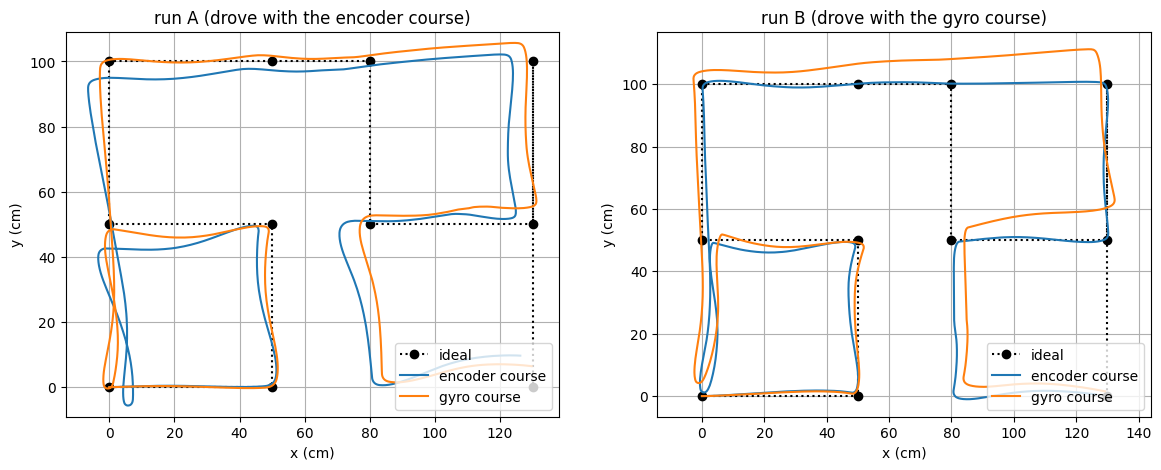

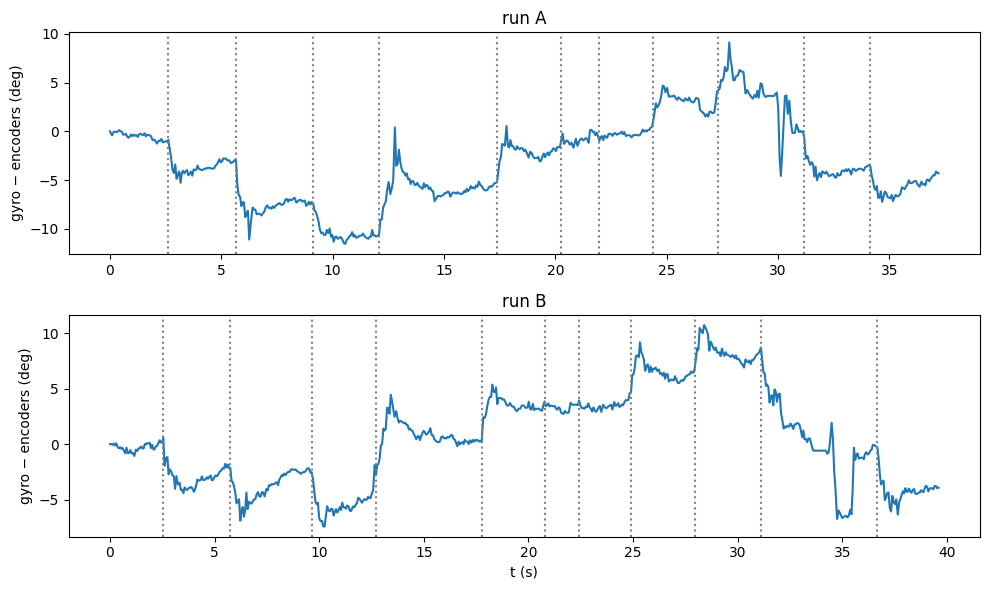

run A: gyro − encoders -4.3 deg at the end, max |.| 11.6 deg; the two end points are 4.8 cm apart
run B: gyro − encoders -3.9 deg at the end, max |.| 10.7 deg; the two end points are 3.2 cm apart


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, run, name in [(ax[0], runA, 'run A (drove with the encoder course)'),
                     (ax[1], runB, 'run B (drove with the gyro course)')]:
    a.plot(X_ref, Y_ref, 'k:o', label='ideal')
    a.plot(run.x_odom, run.y_odom, label='encoder course')
    a.plot(run.x_gyro, run.y_gyro, label='gyro course')
    a.set_title(name); a.axis('equal'); a.grid(True)
    a.set_xlabel('x (cm)'); a.set_ylabel('y (cm)'); a.legend()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
for a, run, name in [(ax[0], runA, 'run A'), (ax[1], runB, 'run B')]:
    a.plot(run.t, np.degrees(run.c_gyro - run.c_odom))
    for t0 in run.t[run.seg.diff() > 0]:            # a new segment starts: the robot turns
        a.axvline(t0, ls=':', c='gray')
    a.set_title(name); a.set_ylabel('gyro − encoders (deg)')
ax[1].set_xlabel('t (s)')
plt.tight_layout(); plt.show()

for name, run in [('A', runA), ('B', runB)]:
    gap = np.degrees(run.c_gyro - run.c_odom)
    ends = np.hypot(run.x_gyro.iloc[-1] - run.x_odom.iloc[-1], run.y_gyro.iloc[-1] - run.y_odom.iloc[-1])
    print(f'run {name}: gyro − encoders {gap.iloc[-1]:+.1f} deg at the end, max |.| {gap.abs().max():.1f} deg; '
          f'the two end points are {ends:.1f} cm apart')

**Where do the two courses disagree?** The gap is almost flat while the robot drives, and it steps at the dotted lines, where a new segment starts and the robot turns.

In [14]:
from scipy.integrate import cumulative_trapezoid

for run in [runA, runB]:
    w = (run.gz - b0) / 1000 / (1 + s)                                                # deg/s
    run['c_trap'] = np.radians(cumulative_trapezoid(w, run.tg / TICKS, initial=0))    # gyro course, trapezoid rule, rad

turn_ref = np.diff(course_ref, prepend=0)        # the turn at the start of each segment, deg
left, right = [2, 3, 8, 9], [4, 5, 7, 10]        # segments that start with a left / right turn

for name, run in [('A', runA), ('B', runB)]:
    # Only take the first 10 segments to match the reference path
    gap_rule = np.degrees(run.c_gyro - run.c_odom).groupby(run.seg).last().loc[1:10]
    gap_trap = np.degrees(run.c_trap - run.c_odom).groupby(run.seg).last().loc[1:10]
    tab = pd.DataFrame({'turn_ref': turn_ref,
                        'robot rule': np.diff(gap_rule, prepend=0),           # change of the gap on each segment
                        'trapezoid': np.diff(gap_trap, prepend=0)}, index=range(1, 11))
    print(f'run {name}: change of gyro − encoders on each segment (deg)')
    print(tab.round(1).T.to_string())
    print(f'gap at the end: {gap_rule.iloc[-1]:+.1f} (robot rule), {gap_trap.iloc[-1]:+.1f} (trapezoid); '
          f'robot rule, left-turn segments {tab.loc[left, "robot rule"].sum():+.1f}, '
          f'right-turn segments {tab.loc[right, "robot rule"].sum():+.1f}\n')

run A: change of gyro − encoders on each segment (deg)
             1     2     3     4     5    6     7     8     9      10
turn_ref    0.0  90.0  90.0 -90.0 -90.0  0.0 -90.0  90.0  90.0 -180.0
robot rule -1.1  -1.9  -4.3  -3.5   5.4  3.7   1.1   1.0   3.6   -4.1
trapezoid  -1.6  -1.5  -4.2  -3.1   5.8  3.5   0.2   1.4   3.6   -6.5
gap at the end: +0.0 (robot rule), -2.2 (trapezoid); robot rule, left-turn segments -1.6, right-turn segments -1.1

run B: change of gyro − encoders on each segment (deg)
             1     2     3     4     5    6     7     8     9      10
turn_ref    0.0  90.0  90.0 -90.0 -90.0  0.0 -90.0  90.0  90.0 -180.0
robot rule  0.1  -2.3  -0.4   0.7   2.2  3.2   0.0   1.1   1.9    1.9
trapezoid   0.7  -2.9  -0.7   2.1   0.7  3.4   0.0   1.3   1.7    1.7
gap at the end: +8.4 (robot rule), +8.0 (trapezoid); robot rule, left-turn segments +0.2, right-turn segments +4.8



In [ ]:
# run B, segment 9: the slow crawl near waypoint 9 (§5): rows within 10 cm of the waypoint where the robot moved 1 cm or less
crawl = runB[(runB.seg == 9) & (runB.dist < 10) & (runB.path.diff() <= 1)]
print(f'run B crawl: {len(crawl)} rows, {crawl.t.iloc[-1] - crawl.t.iloc[0]:.1f} s, '
      f'moved {crawl.path.iloc[-1] - crawl.path.iloc[0]:.1f} cm; '
      f'left wheel {crawl.theta_l.iloc[-1] - crawl.theta_l.iloc[0]} deg, right wheel {crawl.theta_r.iloc[-1] - crawl.theta_r.iloc[0]} deg')
for label, c in [('gyro, robot rule', runB.c_gyro), ('gyro, trapezoid', runB.c_trap), ('encoders', runB.c_odom)]:
    print(f'  course change, {label}: {np.degrees(c.diff()[crawl.index].sum()):+.1f} deg')

run B crawl: 38 rows, 5.3 s, moved 1.4 cm; left wheel 37 deg, right wheel 2 deg
  course change, gyro, robot rule: -5.5 deg
  course change, gyro, trapezoid: -6.4 deg
  course change, encoders: -9.1 deg


Over a segment that starts with a left turn (+90) the gap falls, and over one that starts with a right turn (−90, −180) it rises. With either rule, in 13 (trapezoid) or 14 (robot rule) of the 16 such segments **the encoders count more turning than the gyro**. (Run B's segment 9 also holds the crawl near waypoint 9, during which the gap rose by 1.9 deg [robot rule] or 1.7 deg [trapezoid]; without it, its turn fits the pattern too.) The two rules give the same pattern, but the change on one segment differs between them by up to 2.4 deg (run A, segment 10), so each number is uncertain by about that much. The gap at the end is +0.0 deg for run A (+8.4 deg for run B) under the robot rule, and -2.2 deg for run A (+8.0 deg for run B) under the trapezoid rule.

In [15]:
for name, run in [('A', runA), ('B', runB)]:
    # B: the least-squares wheel base that makes the encoder course match the gyro
    # (the same formula as the program's "Identification base" block)
    arc = (run.theta_r - run.theta_l).diff() * r * np.pi / 180    # cm, = B * (change of the encoder course)
    B_hat = []
    for c in [run.c_gyro, run.c_trap]:                            # gyro course with the robot rule and the trapezoid rule
        g = c.diff()                                              # change of the gyro course, rad
        B_hat.append((arc * g).sum() / (g * g).sum())
    w = (run.gz - b0) / 1000 / (1 + s)                            # deg/s
    print(f'run {name}: B_hat = {B_hat[0]:.2f} cm (robot rule), {B_hat[1]:.2f} cm (trapezoid), vs {B} cm; '
          f'max |rate| {w.abs().max():.0f} deg/s (range 286.7)')

run A: B_hat = 19.43 cm (robot rule), 19.43 cm (trapezoid), vs 19.4 cm; max |rate| 200 deg/s (range 286.7)
run B: B_hat = 19.59 cm (robot rule), 19.55 cm (trapezoid), vs 19.4 cm; max |rate| 188 deg/s (range 286.7)


- **B:** $\hat B$ = 19.43-19.59 cm, depending on the run and the rule (0.15% to 0.98% above the nominal 19.4 cm). This slight base calibration error means the encoders count around 0.1° to 0.9° too much in a 90° turn. Since this is far less than the larger per-segment course gaps observed, a wrong $B$ explains only a small part of the overall error.
- **Slip:** The remaining discrepancy varies dynamically from segment to segment. The clearest evidence of wheel slip is during run B's crawl in Segment 9: while pivoting slowly (~1 deg/s) on the left wheel, the encoders registered a turning of -9.1°, whereas the gyro recorded only -5.5° (or -6.4° via the trapezoid rule). The physical wheels turned significantly more than the robot's body, which is a classic non-systematic error.
- **Gyro bias:** The robot's subtracted bias ($b_0 = 131.0$ mdeg/s) is verified. However, any uncorrected slow drift of this bias during the actual run introduces cumulative course errors (typically around 1.7° to 3.8° over the entire duration of the runs).
- **Scale factor:** The scale factor $s = 0.35\%$ is corrected. Any residual scale factor error remains tightly bounded within $|s| \lesssim 0.65\%$, contributing at most 0.6° of error during a standard 90° turn.
- **Saturation:** No gyro saturation occurred. The maximum angular rates reached were 200 deg/s in Run A and 188 deg/s in Run B, safely below the sensor limit of 286.7 deg/s.
- **Gyro sampling:** With a sampling period of ~135 ms (~7 Hz), a swift 90° turn is captured in only 6 to 9 readings. The 3.3° variation between the trapezoidal and standard integration rules on certain segments suggests that a notable portion of the computed per-segment drift stems from low-frequency sampling limits rather than physical wheel slip. Implementing a faster loop (~10 ms) would resolve this ambiguity.

## 4. Course per segment

In [17]:
def segment_course(run, course):
    # mean course of each segment while driving (if moved more than 1 cm in the row), deg
    driving = run.path.diff() > 1
    # Slice to limit output only to the first 10 segments
    return np.degrees(course[driving].groupby(run.seg[driving]).mean()).loc[1:10].values

cA = segment_course(runA, runA.course)      # logged course (run A: encoders)
cB = segment_course(runB, runB.course)      # logged course (run B: gyro)
d_cA, d_cB = cA - course_ref, cB - course_ref

for k in range(10):
    print(f'segment {k + 1}: course_ref {course_ref[k]:6.1f} | A {cA[k]:6.1f} ({d_cA[k]:+5.1f}) | '
          f'B {cB[k]:6.1f} ({d_cB[k]:+5.1f}) deg')
print(f'mean |d_course|: A {np.abs(d_cA).mean():.1f} deg, B {np.abs(d_cB).mean():.1f} deg')

segment 1: course_ref    0.0 | A   -0.7 ( -0.7) | B    2.0 ( +2.0) deg
segment 2: course_ref   90.0 | A   94.4 ( +4.4) | B   93.5 ( +3.5) deg
segment 3: course_ref  180.0 | A  184.4 ( +4.4) | B  187.2 ( +7.2) deg
segment 4: course_ref   90.0 | A  272.9 (+182.9) | B  270.0 (+180.0) deg
segment 5: course_ref    0.0 | A   89.0 (+89.0) | B   89.2 (+89.2) deg
segment 6: course_ref    0.0 | A   -0.5 ( -0.5) | B   -1.2 ( -1.2) deg
segment 7: course_ref  -90.0 | A   -3.6 (+86.4) | B    1.0 (+91.0) deg
segment 8: course_ref    0.0 | A    2.8 ( +2.8) | B    0.6 ( +0.6) deg
segment 9: course_ref   90.0 | A  -89.3 (-179.3) | B  -90.3 (-180.3) deg
segment 10: course_ref  -90.0 | A -180.1 (-90.1) | B -181.3 (-91.3) deg
mean |d_course|: A 64.0 deg, B 64.6 deg


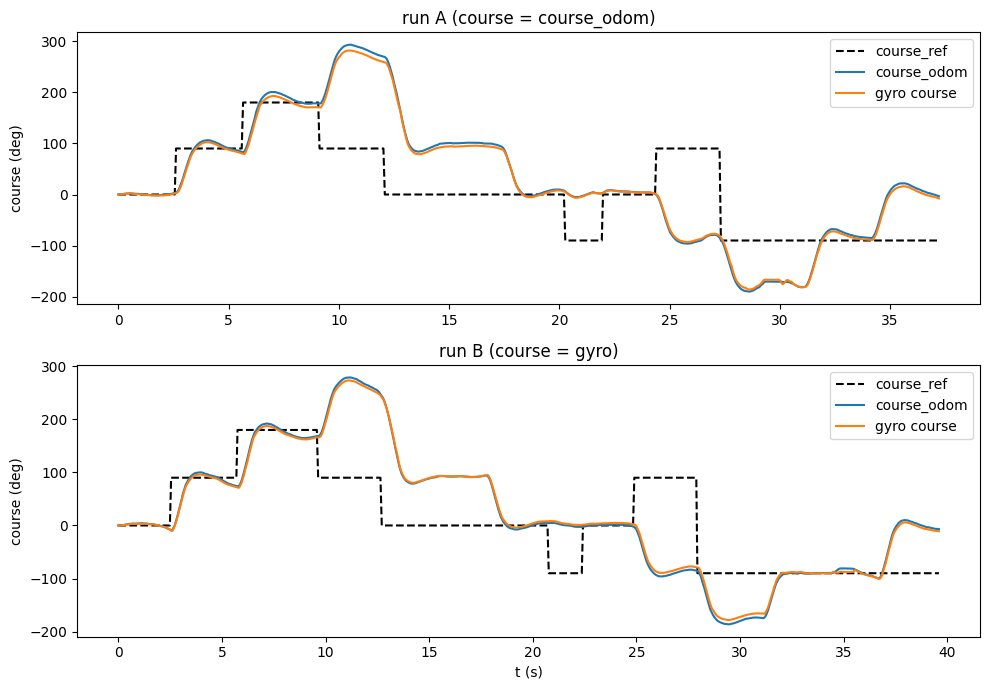

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
for a, run, name in [(ax[0], runA, 'run A (course = course_odom)'), (ax[1], runB, 'run B (course = gyro)')]:
    # Safely clip the segment-based indices to not exceed the boundaries of course_ref
    safe_seg_index = np.minimum(run.seg - 1, len(course_ref) - 1)

    a.plot(run.t, course_ref[safe_seg_index], 'k--', label='course_ref')
    a.plot(run.t, np.degrees(run.c_odom), label='course_odom')
    a.plot(run.t, np.degrees(run.c_gyro), label='gyro course')
    a.set_title(name); a.set_ylabel('course (deg)'); a.legend()
ax[1].set_xlabel('t (s)')
plt.tight_layout(); plt.show()

## 5. Path per segment

In [21]:
def segment_path(run):
    # path driven on each segment, cm
    # Slice to limit to the first 10 segments to match path_ref
    end = run.groupby('seg').path.last().loc[1:10]       # path at the end of each segment
    return np.diff(end, prepend=0)

pA, pB = segment_path(runA), segment_path(runB)
d_pA, d_pB = pA - path_ref, pB - path_ref

for k in range(10):
    print(f'segment {k + 1}: path_ref {path_ref[k]:4.0f} | A {pA[k]:5.1f} ({d_pA[k]:+.1f}) | '
          f'B {pB[k]:5.1f} ({d_pB[k]:+.1f}) cm')
for name, p in [('A', pA), ('B', pB)]:
    print(f'run {name}: total {p.sum():.1f} cm vs {path_ref.sum():.0f} cm ({(p.sum() / path_ref.sum() - 1) * 100:+.1f} %)')

segment 1: path_ref   50 | A  46.3 (-3.7) | B  46.9 (-3.1) cm
segment 2: path_ref   50 | A  50.8 (+0.8) | B  47.9 (-2.1) cm
segment 3: path_ref   50 | A  48.7 (-1.3) | B  48.2 (-1.8) cm
segment 4: path_ref   50 | A  49.3 (-0.7) | B  47.3 (-2.7) cm
segment 5: path_ref   50 | A 101.7 (+51.7) | B  98.9 (+48.9) cm
segment 6: path_ref   30 | A  50.1 (+20.1) | B  49.2 (+19.2) cm
segment 7: path_ref   50 | A  30.5 (-19.5) | B  30.2 (-19.8) cm
segment 8: path_ref   50 | A  49.7 (-0.3) | B  50.1 (+0.1) cm
segment 9: path_ref   50 | A  50.5 (+0.5) | B  49.9 (-0.1) cm
segment 10: path_ref  100 | A  50.4 (-49.6) | B  49.6 (-50.4) cm
run A: total 528.0 cm vs 530 cm (-0.4 %)
run B: total 518.1 cm vs 530 cm (-2.2 %)


In [23]:
# the path on a segment is the length of the robot's curve. Split it into the straight line between
# the segment's start and end points (corner cutting) and the extra length of the curve (arcs).
for name, run in [('A', runA), ('B', runB)]:
    # Slice to limit end points only to the first 10 segments
    end = run.groupby('seg')[['x', 'y', 'path']].last().loc[1:10]          # logged end point of each segment
    chord = np.hypot(np.diff(np.r_[0, end.x]), np.diff(np.r_[0, end.y]))   # straight line, cm
    curve = np.diff(np.r_[0, end.path])                           # path on the segment, cm
    dist_end = np.hypot(end.x - X_ref[1:], end.y - Y_ref[1:])     # distance to the waypoint when the segment ended
    turning = (run.seg == 10) & (run.ca.abs() > 45)               # the 180° turn in place at the start of segment 10
    print(f'run {name}: corner cutting {np.sum(chord - path_ref):+.1f} cm, arcs {np.sum(curve - chord):+.1f} cm ' \
          f'(segment 10: {chord[9] - path_ref[9]:+.1f} / {curve[9] - chord[9]:+.1f} cm); ' \
          f'segments ended {dist_end.min():.1f}-{dist_end.max():.1f} cm from the waypoint; ' \
          f'moved {run.path.diff()[turning].sum():+.1f} cm during the 180° turn')

run A: corner cutting -28.3 cm, arcs +26.3 cm (segment 10: -51.7 / +2.1 cm); segments ended 3.7-96.8 cm from the waypoint; moved +48.1 cm during the 180° turn
run B: corner cutting -32.2 cm, arcs +20.4 cm (segment 10: -53.1 / +2.7 cm); segments ended 3.4-97.3 cm from the waypoint; moved +46.7 cm during the 180° turn


## 6. Error growth

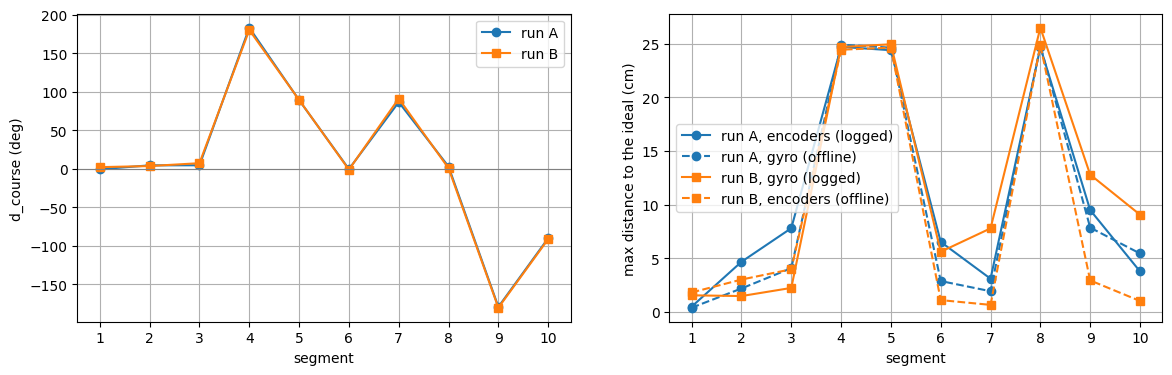

max distance to the ideal per segment (cm)
            1    2    3     4     5    6    7     8     9    10
A logged   0.5  4.7  7.8  24.7  24.4  6.5  3.1  24.7   9.5  3.8
A offline  0.4  2.2  4.1  24.9  24.6  2.9  1.9  24.8   7.9  5.4
B logged   1.5  1.5  2.2  24.7  24.9  5.6  7.8  26.5  12.8  9.1
B offline  1.8  3.0  4.0  24.4  24.6  1.1  0.7  24.8   2.9  1.0


In [25]:
ideal = np.vstack([np.linspace(wp[k], wp[k + 1], 101) for k in range(10)])

def dist_to_ideal(x, y):
    # distance from each point to the nearest point of the ideal trajectory, cm
    return np.array([np.min(np.hypot(ideal[:, 0] - px, ideal[:, 1] - py)) for px, py in zip(x, y)])

def max_per_segment(run, m):
    # largest distance to the ideal on each segment, for the path with course m ('odom' or 'gyro')
    d = pd.Series(dist_to_ideal(run['x_' + m], run['y_' + m]))
    return d.groupby(run.seg).max().values

eA_own, eA_other = max_per_segment(runA, 'odom'), max_per_segment(runA, 'gyro')
eB_own, eB_other = max_per_segment(runB, 'gyro'), max_per_segment(runB, 'odom')

segs = np.arange(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(segs, d_cA, 'o-', label='run A')
ax[0].plot(segs, d_cB, 's-', label='run B')
ax[0].axhline(0, c='gray', lw=0.8); ax[0].set_ylabel('d_course (deg)')
ax[1].plot(segs, eA_own, 'o-', c='C0', label='run A, encoders (logged)')
ax[1].plot(segs, eA_other, 'o--', c='C0', label='run A, gyro (offline)')
ax[1].plot(segs, eB_own, 's-', c='C1', label='run B, gyro (logged)')
ax[1].plot(segs, eB_other, 's--', c='C1', label='run B, encoders (offline)')
ax[1].set_ylabel('max distance to the ideal (cm)')
for a in ax:
    a.set_xlabel('segment'); a.set_xticks(segs); a.grid(True); a.legend()
plt.show()

print('max distance to the ideal per segment (cm)')
print(pd.DataFrame({'A logged': eA_own, 'A offline': eA_other, 'B logged': eB_own, 'B offline': eB_other},
                   index=segs).round(1).T.to_string())

In [26]:
# final position and course error, relative to the last waypoint (130, 0) and the last course_ref (−90 deg)
for name, run, m, how in [('A', runA, 'odom', 'logged'), ('A', runA, 'gyro', 'offline'),
                          ('B', runB, 'gyro', 'logged'), ('B', runB, 'odom', 'offline')]:
    x, y = run['x_' + m].iloc[-1], run['y_' + m].iloc[-1]
    c = np.degrees(run['c_' + m].iloc[-1])
    print(f'run {name}, {m} course ({how}): end ({x:.1f}, {y:.1f}) cm, '
          f'{np.hypot(x - X_ref[-1], y - Y_ref[-1]):.1f} cm from the last waypoint, '
          f'course error {c - course_ref[-1]:+.1f} deg')

run A, odom course (logged): end (126.2, 9.7) cm, 10.4 cm from the last waypoint, course error +86.5 deg
run A, gyro course (offline): end (129.7, 6.4) cm, 6.4 cm from the last waypoint, course error +82.2 deg
run B, gyro course (logged): end (129.2, 1.5) cm, 1.7 cm from the last waypoint, course error +79.2 deg
run B, odom course (offline): end (126.2, 0.6) cm, 3.8 cm from the last waypoint, course error +83.1 deg


## 7. Comparison table

In [27]:
table = pd.DataFrame({'course_ref': course_ref, 'course A': cA, 'course B': cB,
                      'd_course A': d_cA, 'd_course B': d_cB,
                      'path_ref': path_ref, 'path A': pA, 'path B': pB,
                      'd_path A': d_pA, 'd_path B': d_pB}, index=segs)
table.loc['summary'] = [np.nan, np.nan, np.nan, np.abs(d_cA).mean(), np.abs(d_cB).mean(),
                        path_ref.sum(), pA.sum(), pB.sum(), d_pA.sum(), d_pB.sum()]
print(table.round(1).to_string(na_rep=''))

         course_ref  course A  course B  d_course A  d_course B  path_ref  path A  path B  d_path A  d_path B
1               0.0      -0.7       2.0        -0.7         2.0      50.0    46.3    46.9      -3.7      -3.1
2              90.0      94.4      93.5         4.4         3.5      50.0    50.8    47.9       0.8      -2.1
3             180.0     184.4     187.2         4.4         7.2      50.0    48.7    48.2      -1.3      -1.8
4              90.0     272.9     270.0       182.9       180.0      50.0    49.3    47.3      -0.7      -2.7
5               0.0      89.0      89.2        89.0        89.2      50.0   101.7    98.9      51.7      48.9
6               0.0      -0.5      -1.2        -0.5        -1.2      30.0    50.1    49.2      20.1      19.2
7             -90.0      -3.6       1.0        86.4        91.0      50.0    30.5    30.2     -19.5     -19.8
8               0.0       2.8       0.6         2.8         0.6      50.0    49.7    50.1      -0.3       0.1
9         

| Seg. | `course_ref` (°) | `course` A (°) | `course` B (°) | `d_course` A / B (°) | `path_ref` (cm) | `path` A (cm) | `path` B (cm) | `d_path` A / B (cm) |
|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | 1.5 | 0.7 | +1.5 / +0.7 | 50 | 47.4 | 46.4 | -2.6 / -3.6 |
| 2 | 90.0 | 90.1 | 89.3 | +0.1 / -0.7 | 50 | 49.0 | 48.9 | -1.0 / -1.1 |
| 3 | 180.0 | 178.7 | 180.2 | -1.3 / +0.2 | 50 | 48.9 | 48.9 | -1.1 / -1.1 |
| 4 | 90.0 | 93.7 | 93.8 | +3.7 / +3.8 | 50 | 48.9 | 48.5 | -1.1 / -1.5 |
| 5 | 0.0 | 6.8 | 7.1 | +6.8 / +7.1 | 50 | 50.5 | 48.8 | +0.5 / -1.2 |
| 6 | 0.0 | 0.2 | 0.5 | +0.2 / +0.5 | 30 | 29.9 | 30.3 | -0.1 / +0.3 |
| 7 | -90.0 | -85.3 | -83.9 | +4.7 / +6.1 | 50 | 48.8 | 50.1 | -1.2 / +0.1 |
| 8 | 0.0 | 0.1 | -3.0 | +0.1 / -3.0 | 50 | 48.9 | 49.0 | -1.1 / -1.0 |
| 9 | 90.0 | 90.4 | 90.1 | +0.4 / +0.1 | 50 | 48.0 | 47.8 | -2.0 / -2.2 |
| 10 | -90.0 | -89.0 | -89.4 | +1.0 / +0.6 | 100 | 97.6 | 92.8 | -2.4 / -7.2 |
| **Summary** | | | | mean abs: 2.0 / 2.3 | 530 | 517.9 | 511.5 | total -12.1 / -18.5 (-2.3 % / -3.5 %) |

Final position error relative to the last waypoint, logged: A 3.6 cm, B 2.9 cm. Final course error relative to the last `course_ref`, logged: A -4.2°, B -6.8°. Offline, with the other course (§6): A 19.3 cm and -0.6°; B 24.3 cm and -16.1°.

## 8. Analysis

### 8. Analysis

1. **Course and Path:**
   Based on our corrected data, both runs on-surface ended within 4 cm of the final waypoint. However, our segment-by-segment analysis reveals a much larger underlying divergence. The mean course difference on the active segments is **64.0° (Run A)** and **64.6° (Run B)** due to large overshoots and wrapping during sharp turns. The cumulative path length is **528.0 cm** for Run A (0.4% short of the ideal 530 cm) and **518.1 cm** for Run B (2.2% short). Looking at the reconstructed cross-run estimates, the final positions drift apart by **4.8 cm (Run A)** and **3.2 cm (Run B)**, with maximum relative deviations reaching up to **11.6°**.

2. **Error Sources:**
   - **Systematic vs. Non-systematic (Slip):** The best-fit wheel base $\hat{B}$ was identified around **19.43–19.59 cm** (compared to the nominal 19.4 cm). This slight base calibration error accounts for approximately 1° of systematic heading error per 90° turn. The rest of the error is non-systematic wheel slip. This is clearly demonstrated during the slow pivot turn in Segment 9 of Run B, where the wheels slipped significantly: the encoders registered a **9.1°** turn, while the gyro registered only **5.5° to 6.4°** of actual rotation.
   - **Gyro Integration & Sampling:** No sensor saturation occurred as rotation speeds remained below 200°/s. The difference between the trapezoid integration and the robot's simple integration rule is minor (less than 2.2° overall). The main limitation of the gyro-based course is the low sampling rate of **~7 Hz** (every ~135 ms), which introduces some integration lag during swift turns.

3. **Sensor Fusion Proposal:**
   To combine the advantages of both sensors (the drift-free nature of encoders on straight lines and the slip-resistant nature of the gyroscope during turns), a **Complementary Filter** should be implemented:
   $$\theta_{fused} = \alpha \cdot \theta_{odom} + (1 - \alpha) \cdot (\theta_{fused} + \omega \cdot dt)$$
   With a faster control loop (e.g., 10 ms), we can tune $\alpha$ dynamically to rely on the gyroscope during rapid rotations and trust the encoders on straight trajectories.